In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.polynomial import Polynomial

class system:
    def __init__(self, params_y, params_x, params_LQR,
                 mu0=0.1, Sigma0=2.0):
        self.C0, self.C1, self.Znoise = params_y
        self.A, self.B, self.Pnoise = params_x
        self.Q, self.R, self.QT = params_LQR
        self.mu0, self.Sigma0 = mu0, Sigma0

onedcase = system(
    params_y=(0.0, 1.0, 0.09),     # C1 后面设为 alpha；C0 用于扫描
    params_x=(0.9, 1.0, 0.01),
    params_LQR=(1.0, 1.0, 1.0)
)



In [2]:
def Compute_Kt_Pt(s):
    K, P = np.zeros(3), np.zeros(2)
    K[2] = s.QT
    for t in (1, 0):
        P[t] = (s.A*s.B*K[t+1])**2 / (s.B**2*K[t+1] + s.R)
        K[t] = s.Q + s.A**2*K[t+1] - P[t]
    return K, P

s = onedcase
Kt, Pt = Compute_Kt_Pt(s)

alpha = s.B**2*Kt[1] + s.R
beta = s.B*Kt[1]*s.A
gamma = s.Znoise*s.A**2*Pt[1]
kappa = s.Znoise/s.Sigma0

s.C1 = alpha
u_sep = -beta*s.mu0/alpha

print("Kt =", Kt, "\nPt =", Pt)
print("alpha, beta, gamma, kappa =", alpha, beta, gamma, kappa)
print("Sep action =", u_sep)


Kt = [1.47320166 1.405      1.        ] 
Pt = [0.66484834 0.405     ]
alpha, beta, gamma, kappa = 2.4050000000000002 1.2645 0.029524500000000006 0.045
Sep action = -0.05257796257796257


In [3]:
def objective(u, C0, C1, mu=s.mu0):
    u = np.asarray(u)
    f_LQG = alpha*u**2 + 2*beta*mu*u
    g = gamma / ((C0 + C1*u)**2 + kappa)
    return f_LQG, g, f_LQG + g

def argmin_objective(C0, C1, mu=s.mu0):
    u = Polynomial([0., 1.])
    c = C0 + C1*u

    equation = (alpha*u + beta*mu)*(c*c + kappa)**2 - gamma*C1*c
    roots = equation.roots()
    roots = roots[np.abs(roots.imag) < 1e-7].real

    values = objective(roots, C0, C1, mu)[2]
    best = np.isclose(values, values.min(), rtol=1e-9, atol=1e-10)
    return np.sort(roots[best])

The process above is straightforward from the paper listed.

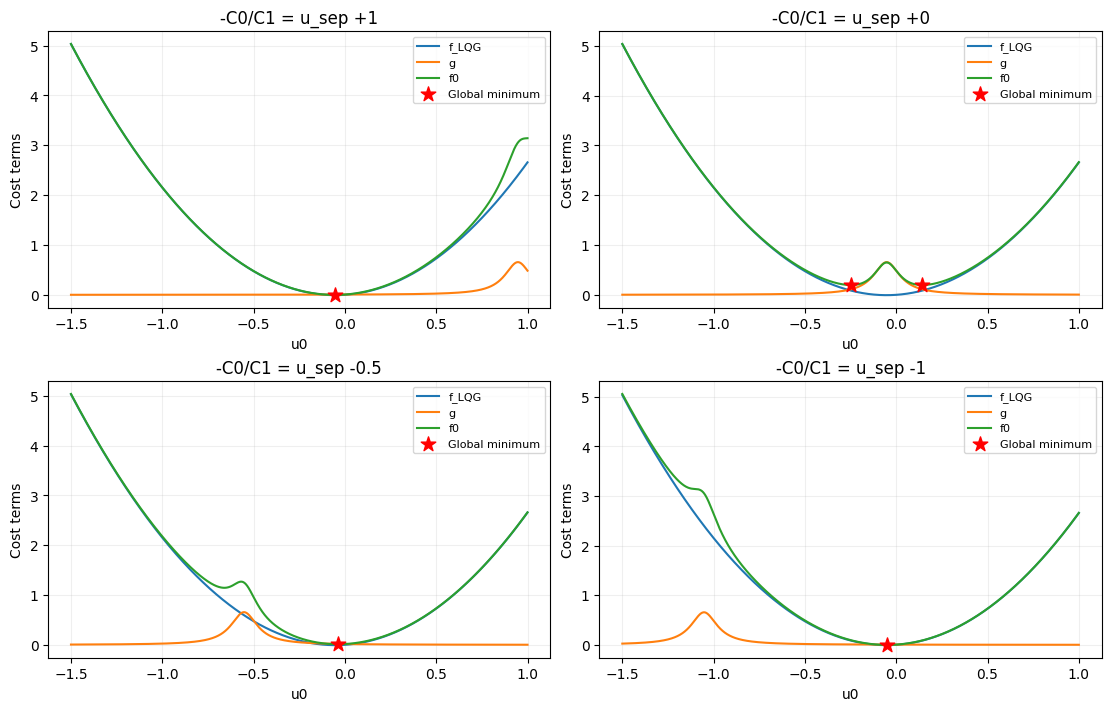

 delta     C0/C1     u_sep               u_opt  J_sep-J_opt
   1.0 -0.947422 -0.052578         [-0.054655]     0.000010
   0.0  0.052578 -0.052578 [-0.248256, 0.1431]     0.453214
  -0.5  0.552578 -0.052578         [-0.037887]     0.000563
  -1.0  1.052578 -0.052578         [-0.050501]     0.000010


In [11]:
deltas = [1.0, 0.0, -0.5, -1.0, -2.0]
u_grid = np.linspace(-1.5, 1.0, 2500)
fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)
rows = []

for ax, delta in zip(axes.flat, deltas):
    C0, C1 = -s.C1*(u_sep + delta), s.C1
    stars = argmin_objective(C0, C1)

    for values, label in zip(objective(u_grid, C0, C1),
                             ["f_LQG", "g", "f0"]):
        ax.plot(u_grid, values, label=label)



    ax.scatter(stars, objective(stars, C0, C1)[2], marker="*",
               s=120, color="red", label="Global minimum", zorder=5)
    ax.set(title=f"-C0/C1 = u_sep {delta:+g}",
           xlabel="u0", ylabel="Cost terms")
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)

    gap = objective(u_sep, C0, C1)[2] - objective(stars[0], C0, C1)[2]
    rows.append([delta, C0/C1, u_sep, np.round(stars, 6).tolist(), gap])

plt.show()
print(pd.DataFrame(rows, columns=[
    "delta", "C0/C1", "u_sep", "u_opt", "J_sep-J_opt"
]).to_string(index=False))

1.The range of u in the paper-suboptimality is from -0.75 to 0.75 in the paper, so that two curves seem totally overlap. But apparently, there should still be a bulge for the orrange curve g.

2.The pictures can show the regularity of the system.
  <1>In the worst case that -C0/C1 = u_sep + 0, the result reconciles with the paper. And the cost difference is appoximately 0.4532.

  <2>In the case when C0 dominates, the influence of covariance seems to be diminished. Thus, the performance of seperation principle can work better.

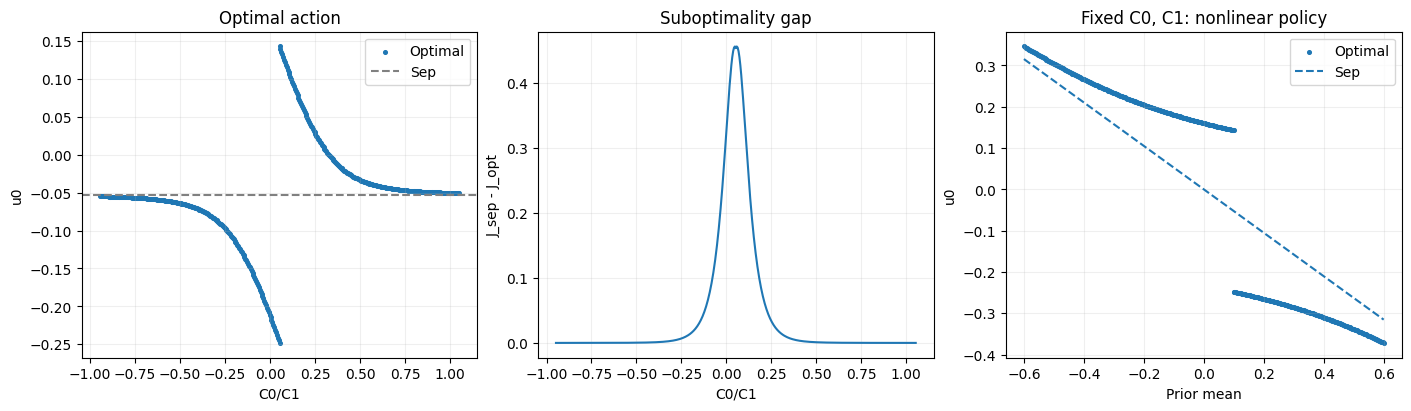

In [9]:
ratios = np.unique(np.r_[np.linspace(-1, 1, 401) - u_sep, -u_sep])
points, gaps = [], []

for ratio in ratios:
    C0 = ratio*s.C1
    stars = argmin_objective(C0, s.C1)
    points.extend((ratio, u) for u in stars)
    gaps.append(objective(u_sep, C0, s.C1)[2]
                - objective(stars[0], C0, s.C1)[2])

points = np.array(points)
fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)

axes[0].scatter(points[:, 0], points[:, 1], s=7, label="Optimal")
axes[0].axhline(u_sep, color="gray", ls="--", label="Sep")
axes[0].set(xlabel="C0/C1", ylabel="u0", title="Optimal action")
axes[0].legend()

axes[1].plot(ratios, gaps)
axes[1].set(xlabel="C0/C1", ylabel="J_sep - J_opt",
            title="Suboptimality gap")

C0 = -s.C1*u_sep
means = np.unique(np.r_[np.linspace(-.6, .6, 401), s.mu0])
points = np.array([(mu, u) for mu in means
                   for u in argmin_objective(C0, s.C1, mu)])

axes[2].scatter(points[:, 0], points[:, 1], s=7, label="Optimal")
axes[2].plot(means, -beta*means/alpha, "--", label="Sep")
axes[2].set(xlabel="Prior mean", ylabel="u0",
            title="Fixed C0, C1: nonlinear policy")
axes[2].legend()

for ax in axes:
    ax.grid(alpha=.2)
plt.show()

These pictures follow our common intuition!

In [12]:
C1, C0 = s.C1, -s.C1*u_sep
radius = np.sqrt(abs(C1)*np.sqrt(gamma/alpha) - kappa) / abs(C1)
u_exact = u_sep + np.array([-radius, radius])

print("Analytic minima:", u_exact)
print("Numeric minima: ", argmin_objective(C0, C1))
print("f0'' at Sep:", 2*alpha - 2*gamma*C1**2/kappa**2)

N = 200_000
rng = np.random.default_rng(0)
x0 = rng.normal(s.mu0, np.sqrt(s.Sigma0), N)
w0, w1 = rng.normal(0, np.sqrt(s.Pnoise), (2, N))
z0 = rng.normal(0, np.sqrt(s.Znoise), N)

def two_step_cost(u0, C0, C1):
    C = C0 + C1*u0
    y0 = C*x0 + z0

    #Observe!
    gain = s.Sigma0*C / (C*C*s.Sigma0 + s.Znoise)
    mu1 = s.A*(s.mu0 + gain*(y0-C*s.mu0)) + s.B*u0
    u1 = -s.A*s.B*s.QT/(s.B**2*s.QT+s.R) * mu1

    x1 = s.A*x0 + s.B*u0 + w0
    x2 = s.A*x1 + s.B*u1 + w1
    return s.Q*(x0*x0+x1*x1) + s.R*(u0*u0+u1*u1) + s.QT*x2*x2

#Cost
constant = (s.Q*(s.mu0**2+s.Sigma0)
            + Kt[1]*(s.A**2*(s.mu0**2+s.Sigma0)+s.Pnoise)
            + (Pt[1]+s.QT)*s.Pnoise)

rows = []
for name, u0 in [("Sep", u_sep),
                 ("Optimal -", u_exact[0]), ("Optimal +", u_exact[1])]:
    costs = two_step_cost(u0, C0, C1)
    rows.append([name, u0, constant+objective(u0, C0, C1)[2],
                 costs.mean(), costs.std(ddof=1)/np.sqrt(N)])

print(pd.DataFrame(rows, columns=[
    "method", "u0", "Exact E[J]", "MC mean", "MC SE"
]).to_string(index=False))

Analytic minima: [-0.24825626  0.14310034]
Numeric minima:  [-0.24825626  0.14310034]
f0'' at Sep: -163.8521690000001
   method        u0  Exact E[J]  MC mean    MC SE
      Sep -0.052578    4.975032 4.985079 0.015724
Optimal - -0.248256    4.521818 4.530267 0.013684
Optimal +  0.143100    4.521818 4.530872 0.013891
